## 1. Imports & config

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# pick up edits to src/ without kernel restarts
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load data

In [102]:
# Checking that the data is loaded correctly
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train:", train.shape, "| Test:", test.shape)
print("Only in train:", set(train.columns) - set(test.columns))

# Quick look at values
display(train.head())
display(train.describe())

Train: (891, 12) | Test: (418, 11)
Only in train: {'Survived'}


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 3. Overview

**Shape:** 891 rows in train; test has the same columns minus `Survived`.

**Columns**

| Role | Columns |
|---|---|
| ID | PassengerId (drop as a feature) |
| Target | Survived (binary) |
| Continuous | Age, Fare |
| Count | SibSp, Parch |
| Nominal | Sex, Embarked |
| Ordinal | Pclass |
| Text / structured | Name, Ticket, Cabin |

**Missing values**
- Age: 177 (~20%) → impute, ideally by group (e.g., median per title)
- Cabin: 687 (~77%) → too sparse to use directly; also many passengers have multiple cabins, drop it
- Embarked: 2 → fill with the most common port
- Test: Fare has 1 missing → fill with the median Fare for that passenger's Pclass

**Takeaways**
- Fare is right-skewed with outliers → check in step 5
- Name holds titles (Mr, Mrs, Miss, Master) → extract in step 7
- SibSp + Parch → family-size feature, view as both count and category

In [103]:
# Checking null values
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 4. Target distribution

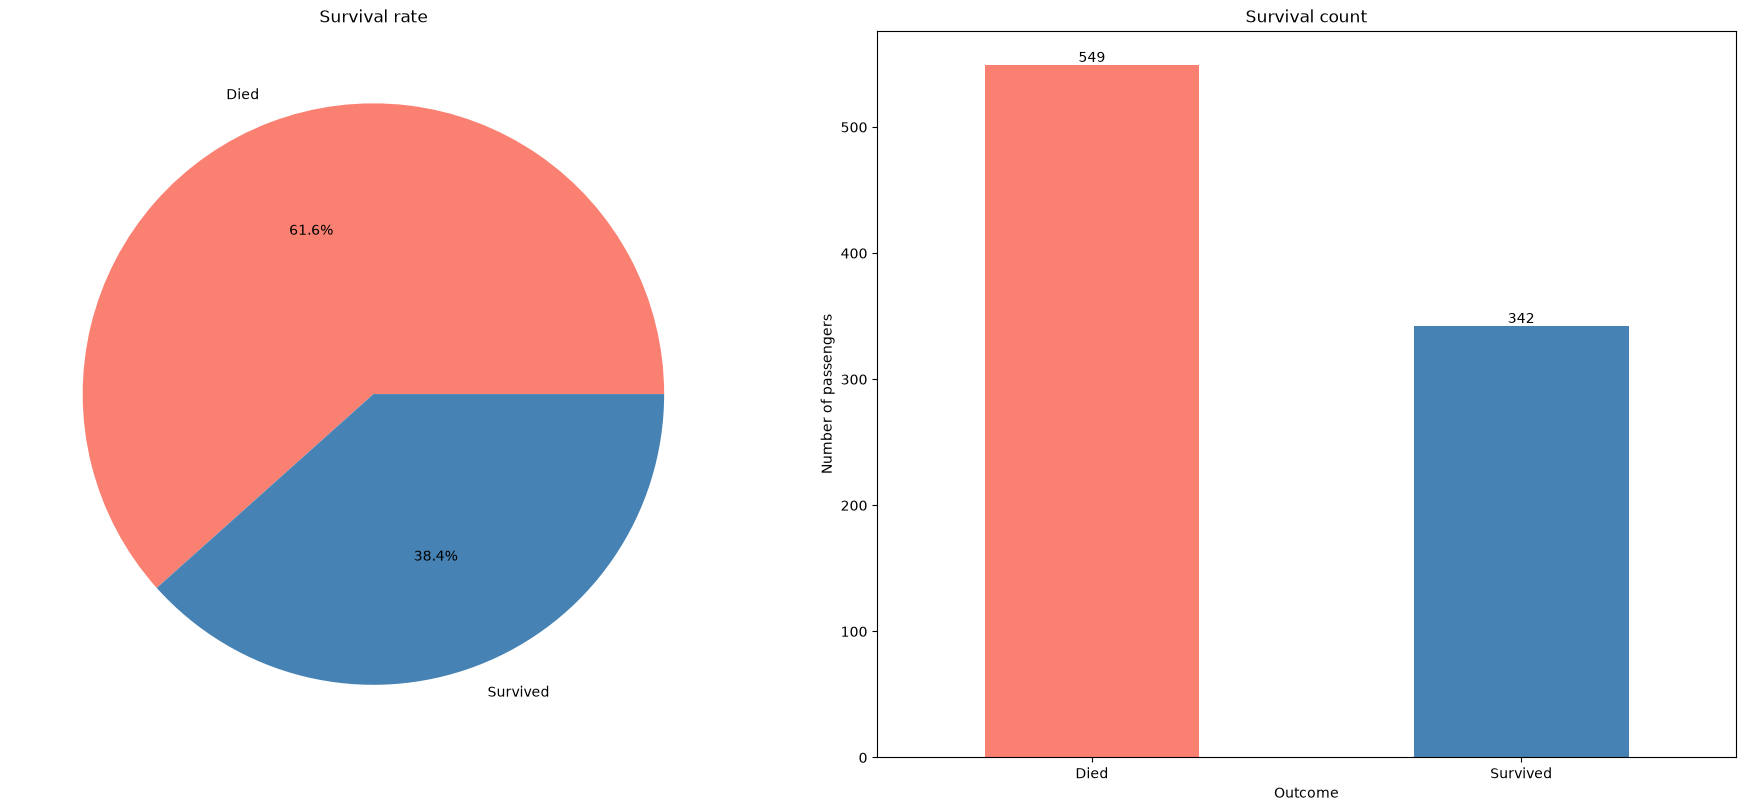

In [104]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
survived = train["Survived"].value_counts().rename({0: 'Died', 1: 'Survived'})
colors = ["salmon", "steelblue"]

survived.plot.pie(autopct='%1.1f%%', ax=ax1, colors=colors)
ax1.set_title('Survival rate')
ax1.set_ylabel('')

survived.plot.bar(ax=ax2, rot=0, color=colors)
ax2.set_title('Survival count')
ax2.set_xlabel('Outcome')
ax2.set_ylabel('Number of passengers')
ax2.bar_label(ax2.containers[0])

plt.show()

60% / 40% split is mildly imbalanced, which in practice counts as fairly balanced. We don’t need special handling, but it still tells us a few useful things:
* Our baseline is 61.6%. A model that always predicts the majority class scores 61.6% accuracy. Our model has to clearly beat that to be learning anything. So an accuracy of 65% sounds decent but is only a small gain over doing nothing.
* No resampling or class weights needed. At 60/40 tree models and logistic regression work fine

## 5. Numerical features

### Age

In [105]:
print('Oldest Passenger was of:',train["Age"].max(),'Years')
print('Youngest Passenger was of:',train["Age"].min(),'Years')
print('Average Age on the ship:',train["Age"].mean(),'Years')

Oldest Passenger was of: 80.0 Years
Youngest Passenger was of: 0.42 Years
Average Age on the ship: 29.69911764705882 Years


**Problem:** 177 missing in train (~20%), 86 in test. Missing rows are mostly
3rd class and have a lower survival rate, so missingness carries signal.

**Options considered**

| Option | Verdict |
|---|---|
| Drop rows | ✗ Loses 20% of train; test still has missing Ages |
| Global median (~28) | ✗ Blurs the child/adult signal |
| Group median by title | ✓ Chosen: cheap and accurate |
| Model-based imputation | ✗ Rarely beats group medians here |
| Leave as NaN | Only for tree models (LightGBM, XGBoost) |

**Why title:** the title in `Name` is a strong age proxy.
Master → boys, Miss → often younger women, Mrs → married women, Mr → adult men.

**Steps** (implemented in `src/features.py`, shared with the pipeline)
1. Add an `Age_missing` flag (0/1) before imputing, to keep the signal.
2. Extract `Title` from `Name`; map Mlle/Ms → Miss, Mme → Mrs;
   group everything else (Dr, Rev, ...) as Other.
3. Compute median Age per Title on train (the `TitanicFeatures` transformer
   learns it in `fit`; inside the pipeline it's re-learned per CV fold).
4. Fill missing Age with the median for that passenger's Title.
5. Verify no missing values remain and re-plot Age.

In [106]:
from src.features import add_title

train, test = add_title(train), add_title(test)

display(pd.crosstab(train["Title"], train["Sex"]).T.style.background_gradient(cmap='summer_r'))

Title,Master,Miss,Mr,Mrs,Other
Sex,,,,,
female,0,185,0,128,1
male,40,0,517,0,20


In [107]:
from src.features import add_age_features

title_age = train.groupby("Title")["Age"].median()

display(title_age)

train, test = add_age_features(train, title_age), add_age_features(test, title_age)

print(train["Age"].isna().sum(), test["Age"].isna().sum())

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Other     49.0
Name: Age, dtype: float64

0 0


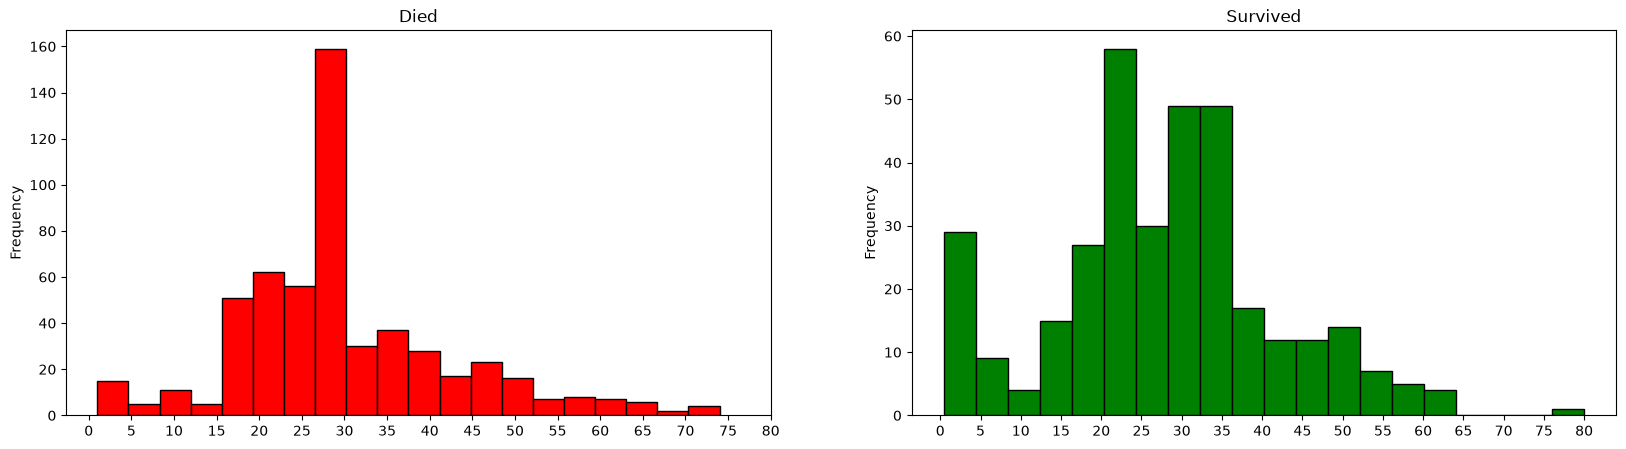

In [108]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))
train[train['Survived'] == 0].Age.plot.hist(ax=ax1, bins=20, edgecolor='black', color='red')
ax1.set_title('Died')
ax1.set_xticks(range(0,85,5))
train[train['Survived']==1].Age.plot.hist(ax=ax2, color='green', bins=20, edgecolor='black')
ax2.set_title('Survived')
ax2.set_xticks(range(0,85,5))
plt.show()

**Observations**:
1) Toddlers (age < 5) had high survival rate 
2) The oldes passenger survived (80 years)
3) Moste of the dead are of age 30-40

**The problem:** Age is a continuous feature: each extra year changes survival odds by the same amount in linear models. On Titanic that's wrong because children survived much more and the effect flattens for adults. We need to convert **continuous values into categorical values** using Binning. We split Age into 5 bins of 16 years (AGE_BINS in src/features.py; the top bin is open-ended, 64+, so unseen old ages can't fall out of range). The AgeBin column is already created by TitanicFeatures above.

In [109]:
display(train.head(2))
display(train["AgeBin"].value_counts().sort_index().to_frame().style.background_gradient(cmap='summer'))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_missing,AgeBin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,0,2


,count
AgeBin,
0,104
1,501
2,205
3,70
4,11


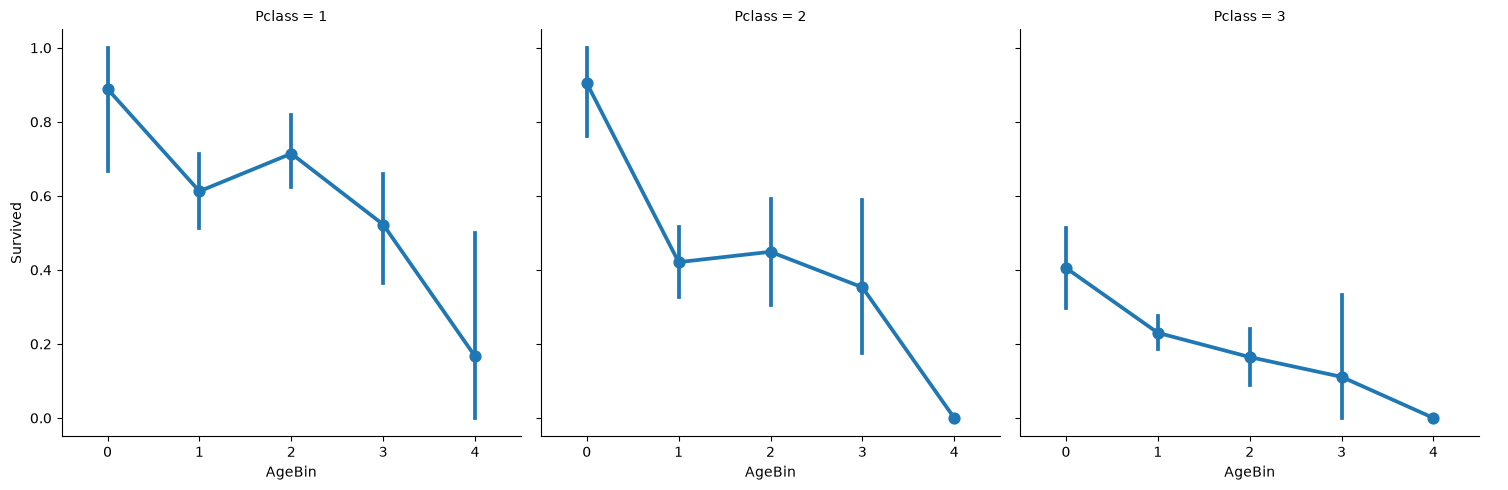

In [110]:
sns.catplot(x="AgeBin", y="Survived", data=train, col="Pclass", kind="point")
plt.show()

The survival rate decreases as the age increases irrespective of the Pclass

### SibSp

This feature shows whether a person is alone or with his siblings/spouse

Sibling = brother, sister, stepbrother, stepsister

Spouse = husband, wife

In [111]:
pd.crosstab([train["SibSp"]], train["Survived"], margins=True).style.background_gradient(cmap='summer_r')

Survived,0,1,All
SibSp,,,
0,398,210,608
1,97,112,209
2,15,13,28
3,12,4,16
4,15,3,18
5,5,0,5
8,7,0,7
All,549,342,891


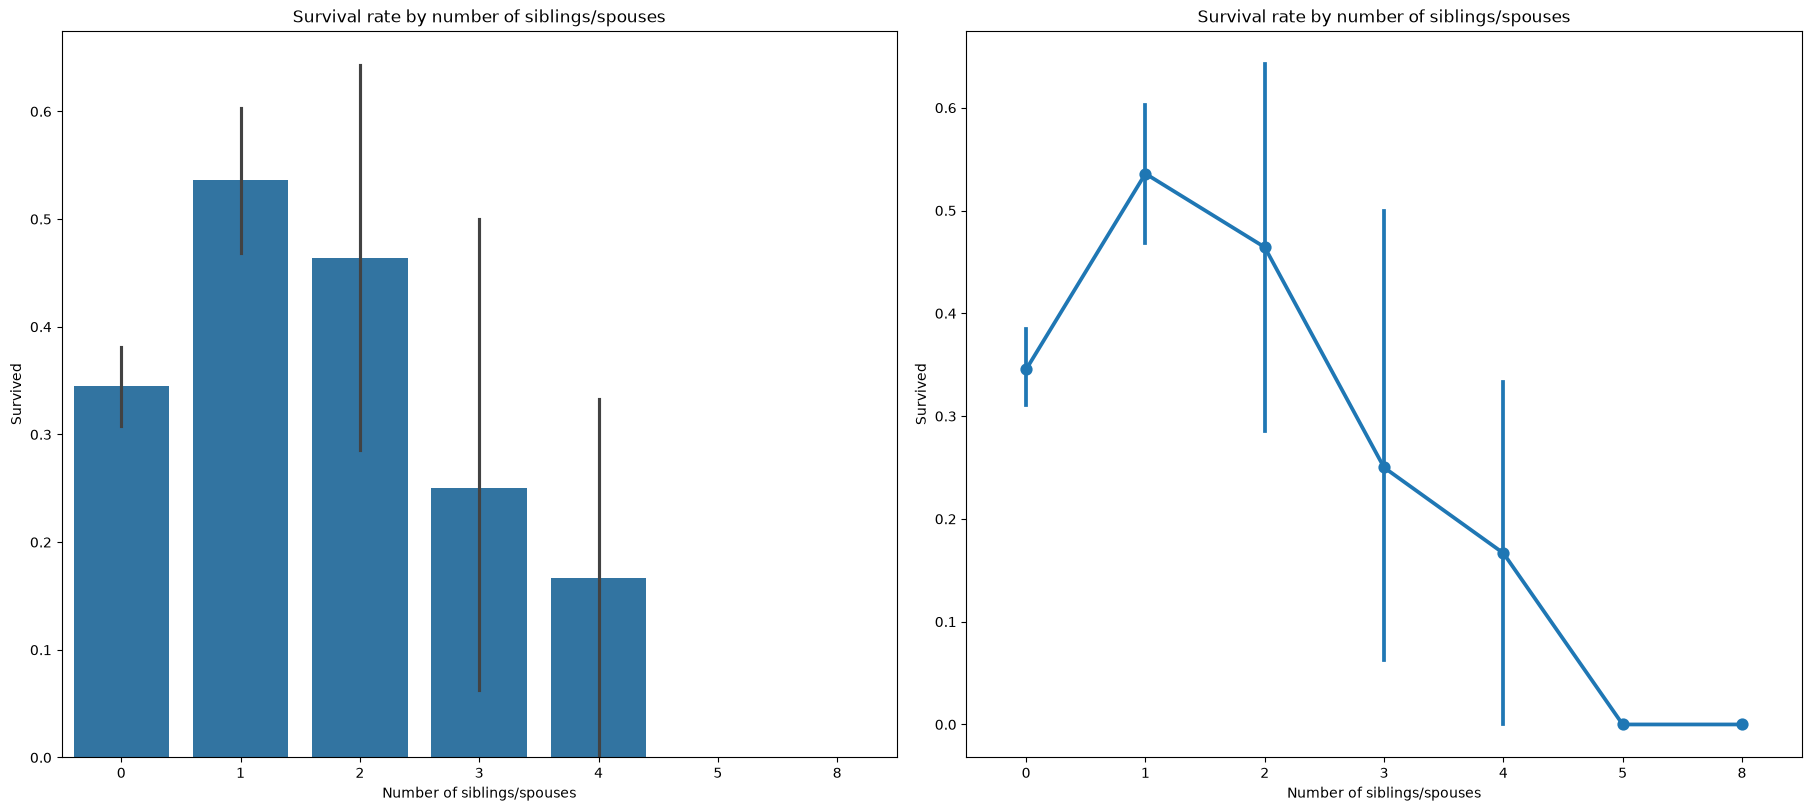

In [112]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
sns.barplot(x="SibSp", y="Survived", data=train, ax=ax1)
ax1.set_title('Survival rate by number of siblings/spouses')
ax1.set_xlabel('Number of siblings/spouses')

sns.pointplot(x="SibSp", y="Survived", data=train, ax=ax2)
ax2.set_title('Survival rate by number of siblings/spouses')
ax2.set_xlabel('Number of siblings/spouses')

plt.show()

In [113]:
pd.crosstab([train["SibSp"]], train["Pclass"], margins=True).style.background_gradient(cmap='summer_r')

Pclass,1,2,3,All
SibSp,,,,
0,137,120,351,608
1,71,55,83,209
2,5,8,15,28
3,3,1,12,16
4,0,0,18,18
5,0,0,5,5
8,0,0,7,7
All,216,184,491,891


**Observations:**

We can see that if a passenger is alone with no siblings they have about 34% survival rate. The survival rate increases if the number of family members increases. Surviving for families with 5-8 members is 0%. The reason is Pclass - passengers with SibSp > 3 were all from class 3.

### Parch

This feature shows the number of parents/children

In [114]:
pd.crosstab([train["Parch"]], train["Pclass"], margins=True).style.background_gradient(cmap='summer_r')

Pclass,1,2,3,All
Parch,,,,
0,163,134,381,678
1,31,32,55,118
2,21,16,43,80
3,0,2,3,5
4,1,0,3,4
5,0,0,5,5
6,0,0,1,1
All,216,184,491,891


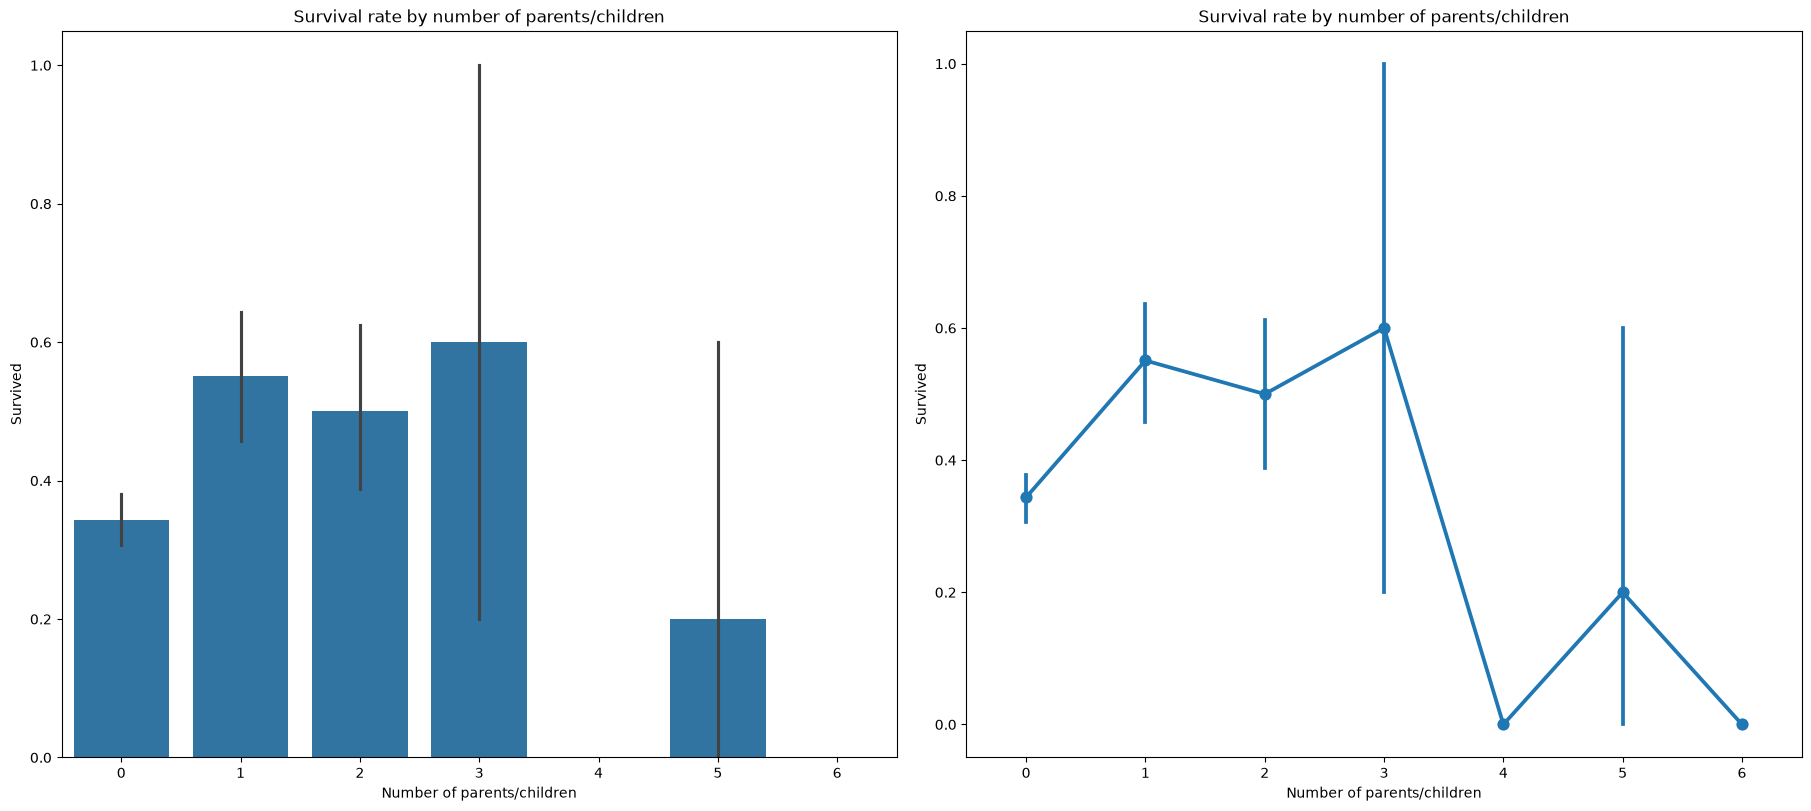

In [115]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
sns.barplot(x="Parch", y="Survived", data=train, ax=ax1)
ax1.set_title('Survival rate by number of parents/children')
ax1.set_xlabel('Number of parents/children')

sns.pointplot(x="Parch", y="Survived", data=train, ax=ax2)
ax2.set_title('Survival rate by number of parents/children')
ax2.set_xlabel('Number of parents/children')

plt.show()

## 6. Categorical features

### Pclass

In [116]:
pd.crosstab(train["Pclass"], train["Survived"], margins=True).style.background_gradient(cmap='summer_r')

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


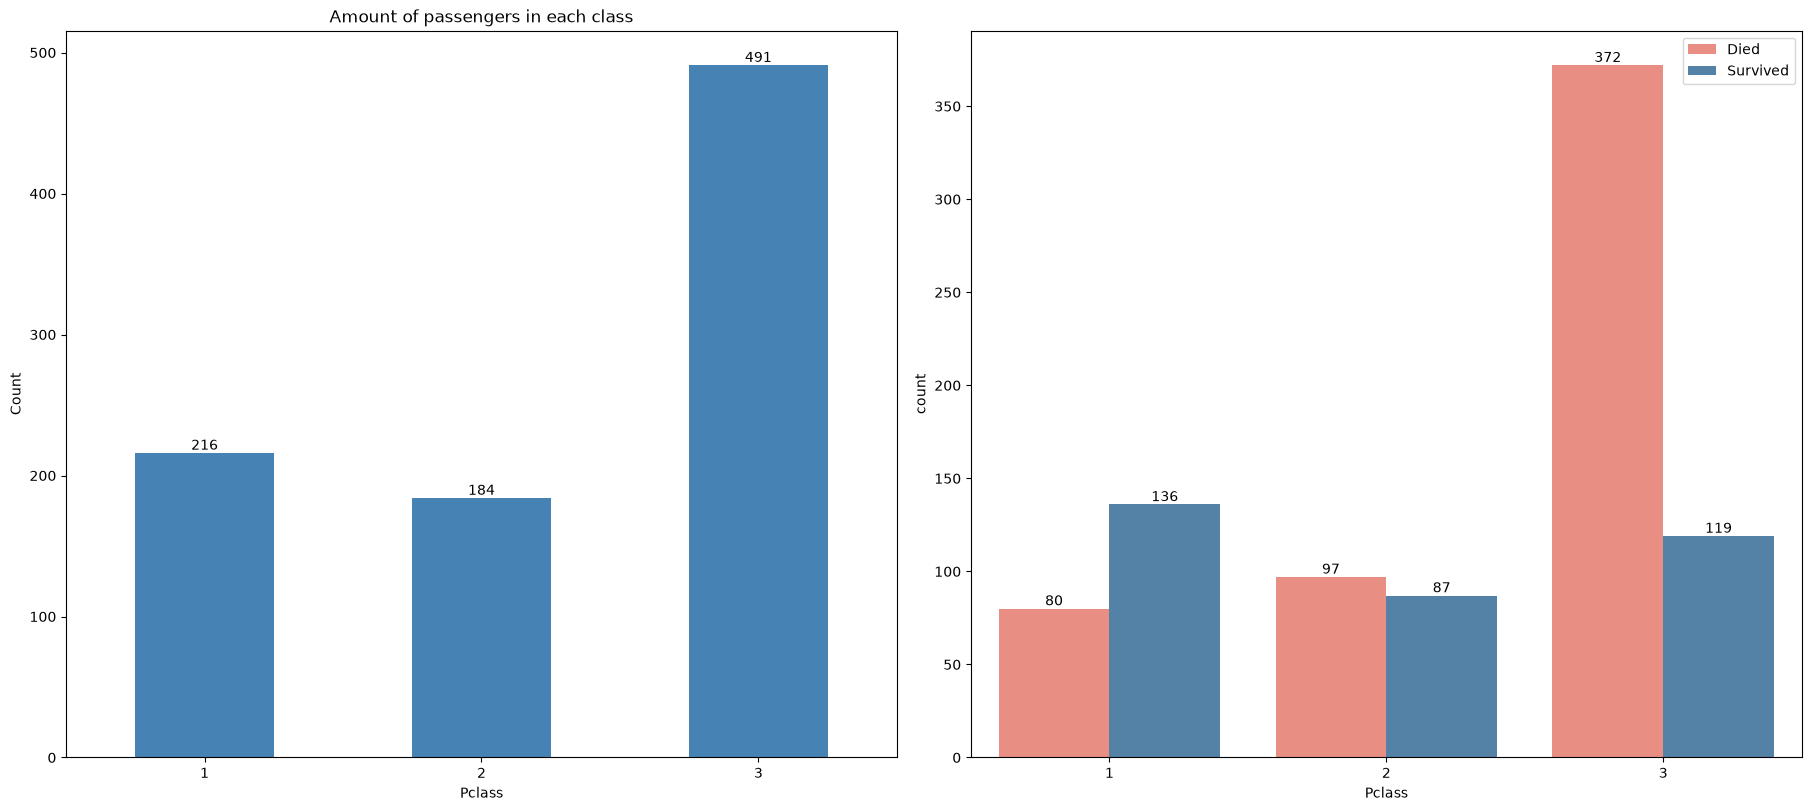

In [117]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
train["Pclass"].value_counts().sort_index().plot.bar(ax=ax1, rot=0, color=["steelblue"])
ax1.set_title('Amount of passengers in each class')
ax1.set_ylabel('Count')
ax1.bar_label(ax1.containers[0])

sns.countplot(x="Pclass", hue="Survived", data=train, ax=ax2, palette=["salmon", "steelblue"])
ax2.legend(title=None, labels=["Died", "Survived"])
for container in ax2.containers:
    ax2.bar_label(container)
plt.show()

We can clearly see that passengers of Class 1 were given a higher priority while rescue even thoug a number of Class 3 passengers were a lot higher. For Class 1 around 63% of passengers survived while for Class 2 survival rate is around 48%.

Now let's check survival rate with Sex and Pclass together.

In [118]:
pd.crosstab([train["Sex"], train["Pclass"]], train["Survived"], margins=True).style.background_gradient(cmap='summer_r')

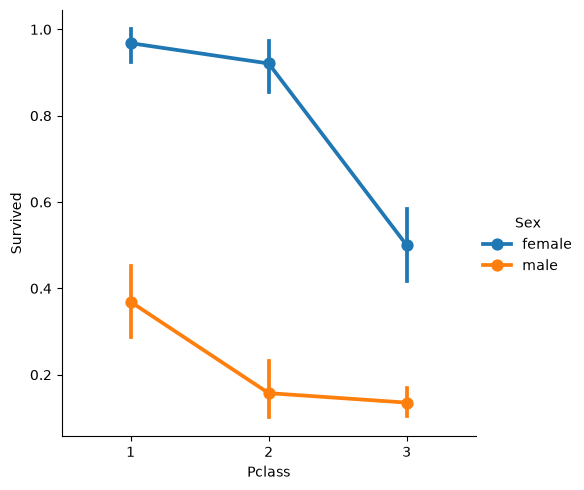

In [119]:
sns.catplot(x="Pclass", y="Survived", data=train, hue="Sex", kind="point")
plt.show()


**Observations:**
1) The gap between the lines is huge -- sex is the dominant factor. The *worst* group of women (3rd class, ~50%) still beats the *best* group of men (1st class, ~37%).
2) Both lines slope down -- class matters for both sexes.
3) The lines are not parallel -- that's an interaction. Women lose most of their advantage between 2nd and 3rd class (92% -> 50%), while men - between 1st and 2nd (37% -> 16%). "Women and children first" apparently worked almost perfectly in classes 1-2 and broke down in 3rd

This plot justifies two things:
* the sex-based baseline ("predict survived iff female" ~ 78% accuracy - the classic `gender_submission`)
* trying `Sex x Pclass` interaction (or Tite, which already blends sex, age, and status) as a feature

### Embarked

In [120]:
pd.crosstab([train["Embarked"], train["Pclass"]], [train["Sex"], train["Survived"]], margins=True).style.background_gradient(cmap='summer_r')

Chances of survival by a prot of embarkation

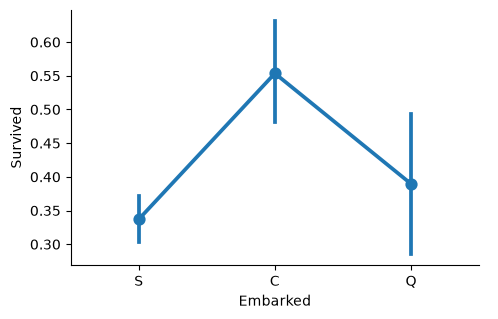

In [121]:
sns.catplot(x="Embarked", y="Survived", data=train, kind="point")
fig=plt.gcf()
fig.set_size_inches(5,3)
plt.show()

The chances of survival for Port C is highest around 0.55 while it's lowest for S

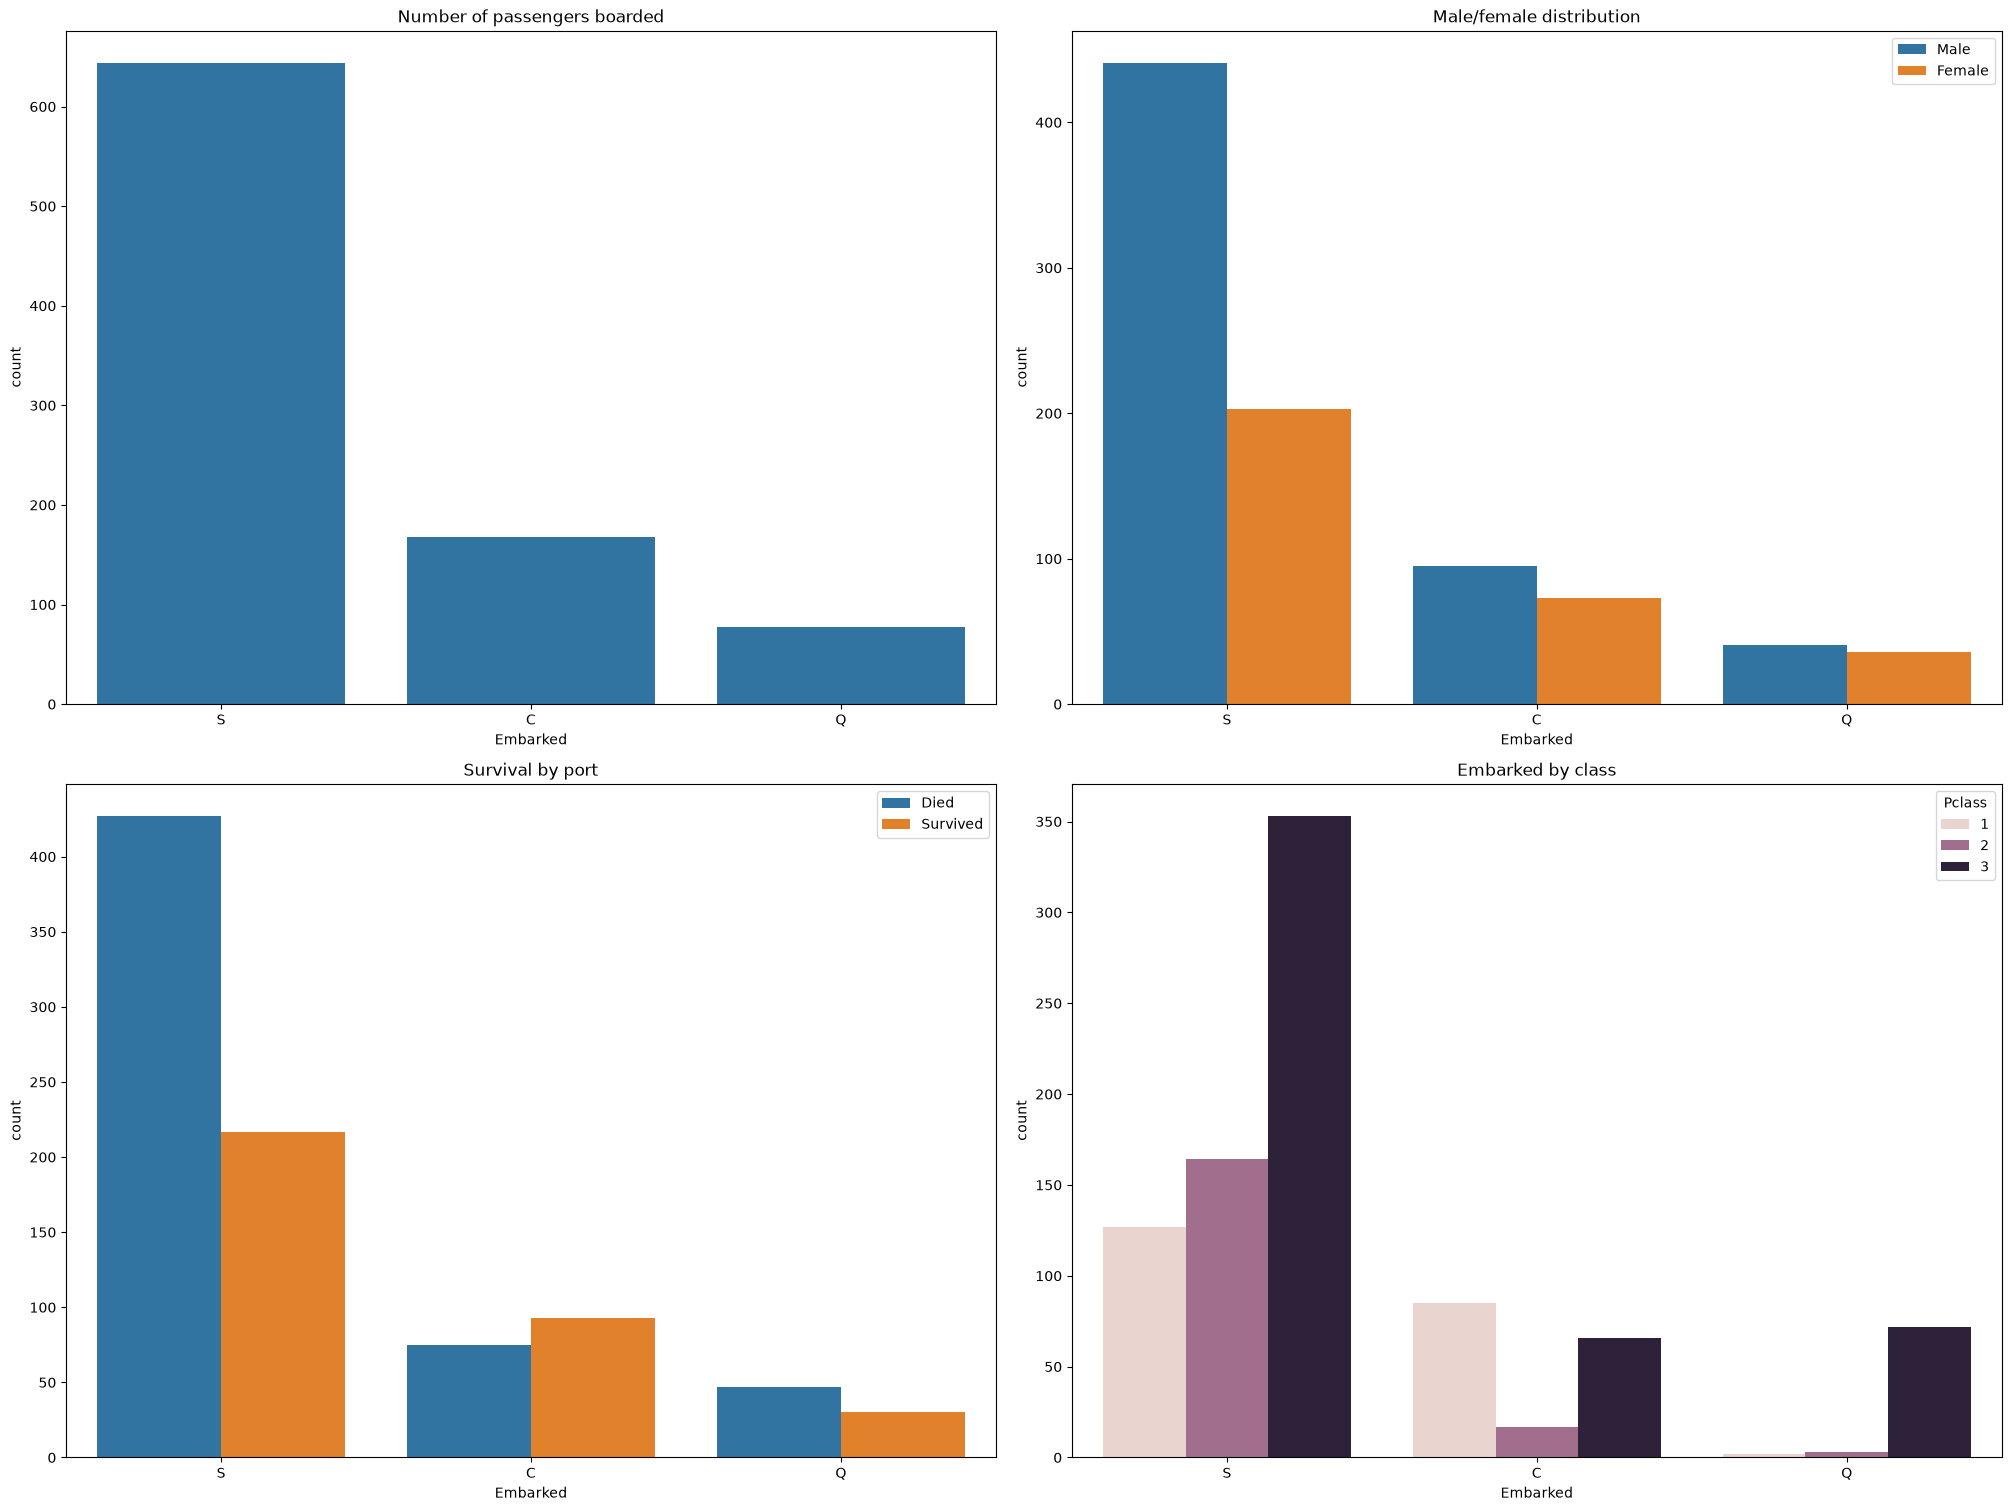

In [122]:
f, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 15), layout='constrained')
sns.countplot(x="Embarked", data=train, ax=ax1)
ax1.set_title('Number of passengers boarded')

sns.countplot(x="Embarked", hue="Sex", data=train, ax=ax2)
ax2.set_title('Male/female distribution')
ax2.legend(title=None, labels=["Male", "Female"])

sns.countplot(x="Embarked", hue="Survived", data=train, ax=ax3)
ax3.set_title('Survival by port')
ax3.legend(title=None, labels=["Died", "Survived"])

sns.countplot(x="Embarked", hue="Pclass", data=train, ax=ax4)
ax4.set_title('Embarked by class')

plt.show()

**Observations:**

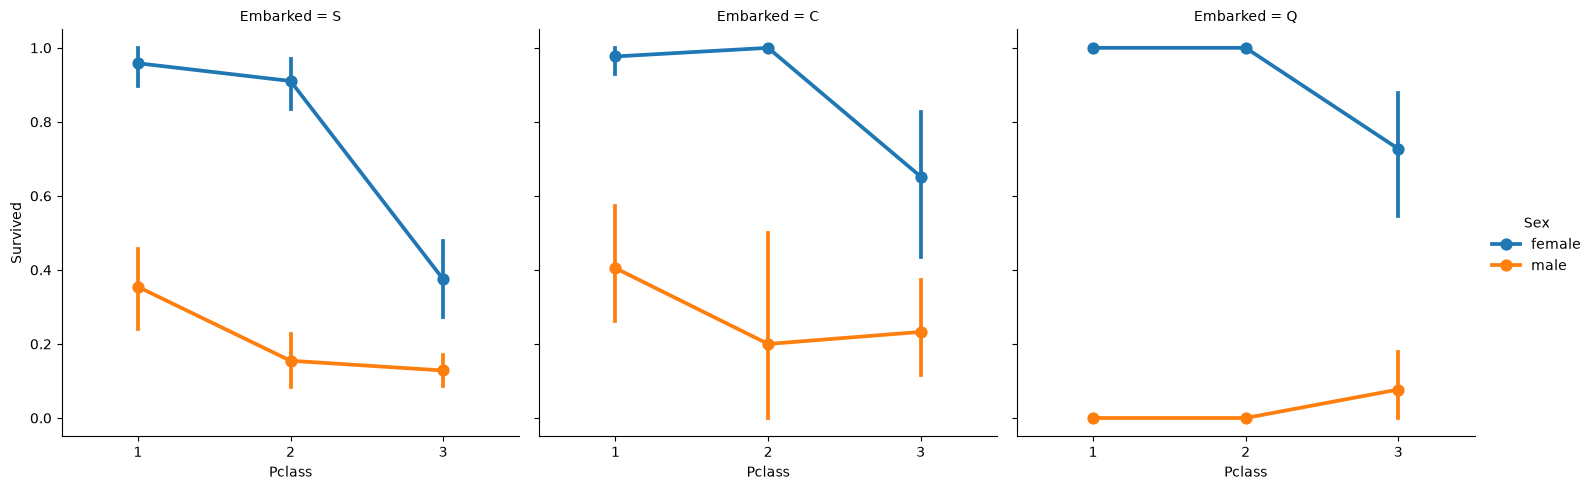

In [123]:
sns.catplot(x="Pclass", y="Survived", hue="Sex", col="Embarked", data=train, kind="point")
plt.show()

**Observations:**
1) Survival rate for women of 1st and 2nd class is almost 1
2) Survival rate for 3rd class passengers including men and women is very low for Port S
3) Almost all men from Port Q died as almost all of them were from 3rd class

#### Filling missing Embarked values

As we've seen the maximum amount of passengers boraded from Port S, so we'll replace NaN with S. In the pipeline it's handled by `SimpleImputer(strategy="most_frequent")`.

In [124]:
train["Embarked"] = train["Embarked"].fillna("S")
train["Embarked"].isnull().any()

np.False_

### Converting string values

Since we cannot pass strings into a ML model, we need to convert categorical features into numeric values. This is handled by `OneHotEncoder(handle_unknown="ignore")` in the pipeline.

In [125]:
train = train.replace({
    "Sex": {"male": 0, "female": 1},
    "Embarked": {"S": 0, "C": 1, "Q": 2},
    "Title": {"Mr": 0, "Mrs": 1, "Miss": 2, "Master": 3, "Other": 4},
})

### Dropping unneeded features

1) **Name** and **PassengerId** cannot be categorized
2) **Age**: we have **AgeBin** feature so we don't need this
3) **Ticket** any random string that cannot be categorized
4) **Cabin**: a lot of NaN values and also many passengers have multiple cabins, useless

In [126]:
train = train.drop(["Name", "PassengerId", "Age", "Ticket", "Fare", "Cabin"], axis=1)

## 8. Correlations

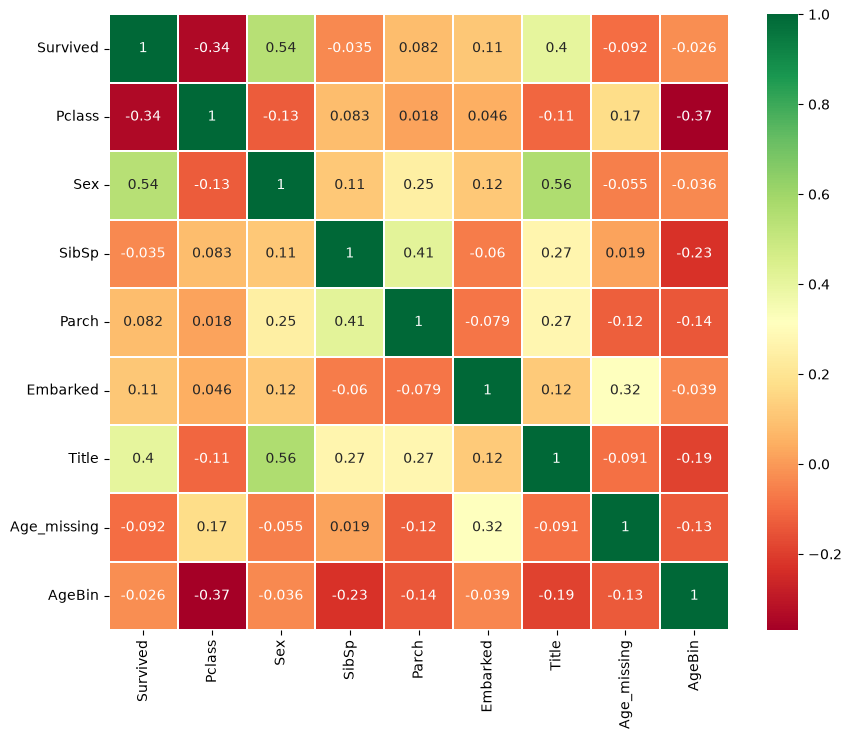

In [127]:
sns.heatmap(train.corr(),annot=True,cmap='RdYlGn',linewidths=0.2)
fig=plt.gcf()
fig.set_size_inches(10,8)
plt.show()

## 9. Train/test drift

Train and test should come from the same distribution, otherwise CV scores won't transfer to the leaderboard. Two checks:

1) Compare each feature separately: KS test for numeric, proportions for categorical

2) Adversarial validation: label train rows 0 and test rows 1, train a classifier to tell them apart. If it can't beat AUC ~0.5, the sets are indistinguishable. This also catches multivariate shifts that per-feature checks would miss

In [128]:
# Per-feature comparison on fresh copies (train/test are mutated by the sections above)
from scipy import stats

tr = pd.read_csv("../data/train.csv")
te = pd.read_csv("../data/test.csv")

for col in ["Age", "Fare", "SibSp", "Parch"]:
    a, b = tr[col].dropna(), te[col].dropna()
    ks, p = stats.ks_2samp(a, b)
    print(f"{col:8s} KS={ks:.3f} p={p:.3f} | median train={a.median():.2f} test={b.median():.2f}")

both = pd.concat([tr.assign(source="train"), te.assign(source="test")])

for col in ["Pclass", "Sex", "Embarked"]:
    display(
        pd.crosstab(both[col], both["source"], normalize="columns")[["train", "test"]]
        .style.format("{:.3f}")
        .background_gradient(cmap="summer_r", axis=1)
    )

Age      KS=0.046 p=0.702 | median train=28.00 test=27.00
Fare     KS=0.039 p=0.751 | median train=14.45 test=14.45
SibSp    KS=0.025 p=0.991 | median train=0.00 test=0.00
Parch    KS=0.014 p=1.000 | median train=0.00 test=0.00


source,train,test
Pclass,,
1,0.242,0.256
2,0.207,0.222
3,0.551,0.522


source,train,test
Sex,,
female,0.352,0.364
male,0.648,0.636


source,train,test
Embarked,,
C,0.189,0.244
Q,0.087,0.110
S,0.724,0.646


In [129]:
# Adversarial validation: can a model tell train rows from test rows?
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked"]

both = pd.concat([tr.assign(is_test=0), te.assign(is_test=1)], ignore_index=True)

adv = Pipeline([
    ("pre", ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])),
    ("rf", RandomForestClassifier(n_estimators=300, random_state=42)),
])

auc = cross_val_score(adv, both[num + cat], both["is_test"], cv=5, scoring="roc_auc")
print(f"Adversarial validation AUC: {auc.mean():.3f} (+/- {auc.std():.3f})")  # ~0.5 = no drift

Adversarial validation AUC: 0.513 (+/- 0.012)


**Results:**

1) KS tests: no significant differences (all p > 0.7), medians basically match
2) Category proportions are close. Biggest gap is Embarked (S: 72% train vs 65% test, C: 19% vs 24%), still small
3) Adversarial validation AUC = 0.51 - a coin flip, the forest can't tell train rows from test rows

**Conclusion:** no drift, the split looks random. CV should track the leaderboard, so if we ever see a big CV-LB gap, the cause is our own leakage or overfitting, not distribution shift.

Note: adversarial validation can't see tiny subsets, e.g. the test-only title Dona (1 row) is invisible to it. That case is covered by the Other title bucket and handle_unknown="ignore" in the pipeline encoder.

## 10. Leakage check

Leakage = information the model sees in training but won't have at prediction time. It inflates CV while the leaderboard stays low. Three checks:

1) Row overlap: the same passenger in both train and test would let the model memorize instead of generalize

2) Too-good-to-be-true features: train on each feature alone. A near-perfect single-feature AUC means the feature encodes the target

3) Row order: PassengerId as a feature should score AUC ~0.5, anything higher means the file ordering correlates with the target

In [130]:
# Train/test row overlap: same passenger in both sets would let a model memorize.
# tr/te are the fresh copies loaded in Section 9.
print("PassengerId overlap:", len(set(tr["PassengerId"]) & set(te["PassengerId"])))
print("Duplicate names within train/test:",
      tr["Name"].duplicated().sum(), "/", te["Name"].duplicated().sum())

shared = set(tr["Name"]) & set(te["Name"])
print("Names in both sets:", shared)

cols = ["Name", "Age", "Ticket", "Pclass", "Embarked"]
display(pd.concat([
    tr[tr["Name"].isin(shared)][cols].assign(source="train"),
    te[te["Name"].isin(shared)][cols].assign(source="test"),
]).sort_values("Name"))

PassengerId overlap: 0
Duplicate names within train/test: 0 / 0
Names in both sets: {'Kelly, Mr. James', 'Connolly, Miss. Kate'}


,Name,Age,Ticket,Pclass,Embarked,source
289,"Connolly, Miss. Kate",22.0,370373,3,Q,train
6,"Connolly, Miss. Kate",30.0,330972,3,Q,test
696,"Kelly, Mr. James",44.0,363592,3,S,train
0,"Kelly, Mr. James",34.5,330911,3,Q,test


In [131]:
# Too-good-to-be-true scan: each feature alone vs the target.
# A single feature with near-perfect AUC would mean target leakage.
y = tr["Survived"]

def single_feature_auc(col: str, is_cat: bool) -> float:
    """CV AUC of a forest trained on one feature only."""
    if is_cat:
        enc = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    else:
        enc = SimpleImputer(strategy="median")
    pipe = Pipeline([
        ("pre", ColumnTransformer([("f", enc, [col])])),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
    ])
    return cross_val_score(pipe, tr[[col]], y, cv=5, scoring="roc_auc").mean()

for col, is_cat in [("Sex", True), ("Pclass", True), ("Fare", False), ("Age", False),
                    ("Embarked", True), ("SibSp", False), ("Parch", False),
                    ("PassengerId", False), ("Ticket", True), ("Cabin", True)]:
    print(f"{col:12s} single-feature AUC = {single_feature_auc(col, is_cat):.3f}")

Sex          single-feature AUC = 0.767
Pclass       single-feature AUC = 0.682
Fare         single-feature AUC = 0.732
Age          single-feature AUC = 0.567
Embarked     single-feature AUC = 0.559
SibSp        single-feature AUC = 0.594
Parch        single-feature AUC = 0.574
PassengerId  single-feature AUC = 0.468
Ticket       single-feature AUC = 0.645
Cabin        single-feature AUC = 0.630


**Results:**

1) No row overlap: PassengerId sets are disjoint. Two names appear in both sets (Kelly, Mr. James and Connolly, Miss. Kate) but ages and tickets don't match - just namesakes, not duplicates
2) No suspiciously strong features: the best single feature is Sex (AUC 0.77), which matches the EDA. Nothing near the 0.95+ zone that would mean the feature encodes the target
3) PassengerId alone scores AUC ~0.5, so row order carries no signal
4) Ticket (0.65) and Cabin (0.63) do carry signal (shared tickets = groups, cabin known ~ 1st class) - that's real information to use, not leakage

About our own preprocessing:
* Age imputation is a fitted pipeline step (TitanicFeatures): title medians are re-learned inside each CV fold, so validation rows never contribute to the values that fill them
* Encoders and imputers are also fit inside CV folds by the sklearn Pipeline, so no fold leakage anywhere

**Conclusion:** no target leakage, no train/test contamination. CV scores can be trusted (consistent with the drift check in section 9).

## 11. Key takeaways

## 12. Baseline model

Every model needs a floor to compare against. Three baselines of increasing effort:

1) Majority class: predict "died" for everyone (no model at all)

2) One rule: female = survived, male = died. This is exactly what gender_submission.csv does

3) Logistic regression on raw features (no feature engineering) - the simplest trainable model

In [132]:
# Rule baselines + simplest real model. tr/te are the fresh copies from section 9.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

y = tr["Survived"]

print(f"majority (all died):     {(y == 0).mean():.4f}")
print(f"sex rule (female lives): {(tr['Sex'].eq('female').astype(int) == y).mean():.4f}")

num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked"]

logreg = Pipeline([
    ("pre", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])),
    ("lr", LogisticRegression(max_iter=2000)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(logreg, tr[num + cat], y, cv=cv, scoring="accuracy")
print(f"logreg CV:               {scores.mean():.4f} (+/- {scores.std():.4f})")

majority (all died):     0.6162
sex rule (female lives): 0.7868
logreg CV:               0.7969 (+/- 0.0146)


In [133]:
# Sex x Pclass interaction (promised in the Pclass section): logreg can't learn it
# from separate features, so we add the combined category explicitly
tr["SexPclass"] = tr["Sex"] + "_" + tr["Pclass"].astype(str)

inter = Pipeline([
    ("pre", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
         cat + ["SexPclass"]),
    ])),
    ("lr", LogisticRegression(max_iter=2000)),
])

scores = cross_val_score(inter, tr[num + cat + ["SexPclass"]], y, cv=cv, scoring="accuracy")
print(f"logreg + Sex x Pclass:   {scores.mean():.4f} (+/- {scores.std():.4f})")

logreg + Sex x Pclass:   0.8103 (+/- 0.0166)


**Results:**

| Baseline | Accuracy |
|---|---|
| Majority class (everyone dies) | 0.616 |
| Sex rule (female = survived) | 0.787 |
| Logreg on raw features, 5-fold CV | 0.797 |
| Logreg + Sex x Pclass interaction | 0.810 |

**Conclusion:** the real bar to beat is ~0.79-0.80, not 0.62. The sex rule alone gets 0.787 (it's literally gender_submission.csv, ~0.766 on the public LB), and logreg on raw features barely improves on it.

The Sex x Pclass interaction from the Pclass section checks out: adding the combined category gives logreg +1.3 points (0.797 -> 0.810), close to the random forest on the same kind of features (0.82 in main.py with Title/AgeBin/Age_missing). This confirms the non-parallel lines story: the forest was ahead mostly because it finds interactions on its own, and once we hand one to logreg explicitly, the gap nearly closes. Takeaway for the final project: for linear models, interactions have to be built as features; trees get them for free.